# De relatie tussen dagelijks gebruik van short-form video’s en werkgeheugenprestatie bij studenten
### Analyze en figuren
**Onderzoeksvraag**: Wat is het verband tussen de gemiddelde tijd per dag die studenten aan short-form video's besteden en hun werkgeheugenprestatie op een 2-back-taak?

**Hypothese**:
- Hoofdvoorspelling: Hoe meer minuten per dag een student aan short-form video's besteedt, hoe lager de accuratesse op de 2-back-taak is.
- Nevenvoorspelling: Hoe meer minuten per dag een student aan short-form video's besteedt, hoe langer de reactietijden op de 2-back-taak zijn.

### Survey
| Vraag | Antwoord | Type |
|---|---|---|
|Leeftijd | jaar | int |
|Gender | man, vrouw, anders, zeg ik liever niet | enum |
|Shortform duur per dag | min | int |
|Shortform bron |opgezocht, geschat | enum |
|Slaap duur | uur | int |

### Task
N-Back test (N = 2) afgenomen op PsyToolkit (https://www.psytoolkit.org/c/3.7.6/survey?s=m8JRm)

### Onderzoek
| Rol | Variabele | Bron |
|---|---|---|
| Onafhankelijke variabele | `shortform_min`: zelfgerapporteerde minuten per dag | survey |
| Primaire uitkomstmaat | `accuracy`: gecorrigeerde trefferkans | `experiment_data/` |
| Secundaire uitkomstmaat | `rt_median`: gemiddelde reactietijd op treffers in ms | `experiment_data/` |
| Covariate | `slaap`: zelfgerapporteerde aantal uur geslapen afgelopen nacht | survey |
| Sensitiviteitsanalyse | `shortform_bron`: opgezocht of geschat | survey |


In [137]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05
DATA = Path("data")

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

# style ✨
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

## Survey data

Codes (`survey.txt`):
- `consent`: 1 = ja, 2 = nee
- `gender`: 1 = man, 2 = vrouw, 3 = anders, 4 = zeg ik liever niet
- `shortform_bron`: 1 = opgezocht, 2 = geschat

In [138]:
# read data from csv
survey = pd.read_csv("./data/data.csv")

# convert and drop colums
survey["uuid"] = survey["participant"].str.split(".").str[1]
survey["consent"] = survey["consent"].map({1: "ja", 2: "nee"})
survey["gender_label"] = survey["gender"].map({1: "man", 2: "vrouw", 3: "anders", 4: "zeg ik liever niet"})
survey["bron_label"] = survey["shortform_bron"].map({1: "opgezocht", 2: "geschat"})
survey = survey[["uuid", "consent", "leeftijd", "gender_label", "shortform_min", "bron_label", "slaap"]]

# remove entries with no consent
survey = survey[survey['consent'] == 'ja']
survey = survey.reset_index(drop=True)

display(survey)

,uuid,consent,leeftijd,gender_label,shortform_min,bron_label,slaap
0,06ac6dd9-2581-4147-a11b-08da3cbed35e,ja,21.0,vrouw,88.0,opgezocht,6.0
1,10ecf204-6e66-479d-9418-7c05b860ee7e,ja,23.0,vrouw,20.0,opgezocht,9.0
2,252c0ccc-6b8b-48b5-968b-4fa9832ee01f,ja,21.0,man,180.0,opgezocht,6.0
3,2614051e-694e-4476-80c7-c5a2d1c9e8e5,ja,20.0,anders,60.0,opgezocht,8.0
4,3798b14a-1955-49fb-a3b7-26004923a6ac,ja,20.0,vrouw,40.0,opgezocht,10.0
5,3e84d5fd-2dcf-40f0-bb08-43427945129d,ja,19.0,vrouw,360.0,opgezocht,7.0
6,63359fbc-512e-4b0c-b45a-fbcc668dd068,ja,20.0,man,120.0,geschat,6.0
7,73b3b8e0-d90c-40b1-95ae-7500b6d1896f,ja,20.0,vrouw,240.0,opgezocht,7.0
8,75799c25-1be6-4e28-ab18-b2b888f8b6f9,ja,23.0,man,90.0,geschat,6.0
9,8f8d17b9-d72d-4f76-b254-a842afa2a753,ja,19.0,vrouw,150.0,opgezocht,7.0


## Task data
Voor elk participant die de task heeft afgerond is er een data bestand met de resultaten in `data/experiment_data/`.

Elk bestand bestaad uit rijen, een rij stelt een trail voor.
Er waren 3 tests (blok) van 25 trails, geeft: 3 x 25 = 75 rijen per bestand.

Uit de door PsyToolkit geleverde r script `data/analize_nback2.r`, hebben we de volgende kolommen afgeleidt:

| kolom | naam | betekenis |
|---|---|---|
| 1 | `block` | 1 = practice, 2–3 = test |
| 2 | `trial` | trial nummer in de blok |
| 3 | `target` | 1 = de letter is hetzelfde als twee ervoor |
| 4 | `correct` | 1 = correct response |
| 5–7 | `hit`, `miss`, `false_alarm` | uitkomst |
| 8 | `rt` | reactietijd in ms; 3000 = geen invoer |
| 9–12 | | niet relevant |

In [139]:
trial_cols = ["block", "trial", "target", "correct", "hit", "miss", "false_alarm", "rt", "9", "10", "11", "12"]

# load by iterating over the files in experiment_data
frames = []
for file in (DATA / "experiment_data").glob("nback2.*.txt"):
    df = pd.read_csv(file, sep=r"\s+", header=None, names=trial_cols)
    df["uuid"] = file.name.split(".")[3]
    frames.append(df)

trials = pd.concat(frames, ignore_index=True)
trials = trials[["uuid", "block", "trial", "target", "correct", "hit", "miss", "false_alarm", "rt"]]

# remove incomplete entries (survey only contains completed entries)
trials = trials[trials["uuid"].isin(survey.uuid.unique())]

# remove practice trials (block 2-3)
trials = trials[trials["block"] > 1]

print(f"{len(trials.uuid.unique())} participanten, {len(trials)} trials")

display(trials)


16 participanten, 800 trials


,uuid,block,trial,target,correct,hit,miss,false_alarm,rt
25,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,1,0,1,0,0,0,3000
26,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,2,0,1,0,0,0,3000
27,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,3,0,1,0,0,0,3000
28,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,4,0,1,0,0,0,3000
29,a601c3ea-a71e-4160-a2b9-d798da2810b1,2,5,1,1,1,0,0,972
...,...,...,...,...,...,...,...,...,...
1270,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,21,0,1,0,0,0,3000
1271,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,22,0,1,0,0,0,3000
1272,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,23,0,1,0,0,0,3000
1273,8f8d17b9-d72d-4f76-b254-a842afa2a753,3,24,0,1,0,0,0,3000


## Task measures
De volgende task measures worden berekend over de test blocks:
- Hit rate = hit / targets
- False alarm rate = false alarms / non-targets
- Accuracy = verhouding van alle trials dat correct is
- Reaction time median
- Reaction time mean

In [140]:
def task_measures(tr: pd.DataFrame) -> pd.DataFrame:
    def one(d):
        target = d[d.target == 1]
        non_target = d[d.target == 0]

        hits = target.correct.sum()
        fas = (non_target.false_alarm).sum()

        hit_rt = target.loc[target.correct == 1, "rt"]

        return pd.Series({
            "n_trials": len(d),
            "n_targets": len(target),
            "hits": hits,
            "false_alarms": fas,
            "hit_rate": hits / len(target),
            "fa_rate": fas / len(non_target),
            "accuracy": d.correct.mean(),
            "rt_median": hit_rt.median(),
            "rt_mean": hit_rt.mean(),
            "n_rt": len(hit_rt),
        })
    return tr.groupby("uuid")[tr.columns.drop("uuid")].apply(one)

dataset = survey.merge(task_measures(trials), left_on="uuid", right_index=True, how="left")
display(dataset)

,uuid,consent,leeftijd,gender_label,shortform_min,bron_label,slaap,n_trials,n_targets,hits,false_alarms,hit_rate,fa_rate,accuracy,rt_median,rt_mean,n_rt
0,06ac6dd9-2581-4147-a11b-08da3cbed35e,ja,21.0,vrouw,88.0,opgezocht,6.0,50.0,20.0,20.0,1.0,1.000,0.033,0.98,400.5,451.200,20.0
1,10ecf204-6e66-479d-9418-7c05b860ee7e,ja,23.0,vrouw,20.0,opgezocht,9.0,50.0,20.0,15.0,0.0,0.750,0.000,0.90,563.0,560.133,15.0
2,252c0ccc-6b8b-48b5-968b-4fa9832ee01f,ja,21.0,man,180.0,opgezocht,6.0,50.0,16.0,10.0,1.0,0.625,0.029,0.86,642.5,661.900,10.0
3,2614051e-694e-4476-80c7-c5a2d1c9e8e5,ja,20.0,anders,60.0,opgezocht,8.0,50.0,15.0,11.0,0.0,0.733,0.000,0.92,641.0,641.000,11.0
4,3798b14a-1955-49fb-a3b7-26004923a6ac,ja,20.0,vrouw,40.0,opgezocht,10.0,50.0,12.0,11.0,1.0,0.917,0.026,0.96,422.0,443.000,11.0
5,3e84d5fd-2dcf-40f0-bb08-43427945129d,ja,19.0,vrouw,360.0,opgezocht,7.0,50.0,14.0,7.0,2.0,0.500,0.056,0.82,453.0,608.429,7.0
6,63359fbc-512e-4b0c-b45a-fbcc668dd068,ja,20.0,man,120.0,geschat,6.0,50.0,20.0,20.0,4.0,1.000,0.133,0.92,429.0,517.750,20.0
7,73b3b8e0-d90c-40b1-95ae-7500b6d1896f,ja,20.0,vrouw,240.0,opgezocht,7.0,50.0,14.0,10.0,2.0,0.714,0.056,0.88,701.0,710.000,10.0
8,75799c25-1be6-4e28-ab18-b2b888f8b6f9,ja,23.0,man,90.0,geschat,6.0,50.0,10.0,7.0,3.0,0.700,0.075,0.88,616.0,617.429,7.0
9,8f8d17b9-d72d-4f76-b254-a842afa2a753,ja,19.0,vrouw,150.0,opgezocht,7.0,50.0,14.0,9.0,4.0,0.643,0.111,0.82,594.0,621.556,9.0


## Descriptive statistics

In [141]:
N = len(dataset)

print(f"N = {N}")
print(f"Age: M = {dataset.leeftijd.mean():.1f}, SD = {dataset.leeftijd.std():.1f}, range {int(dataset.leeftijd.min())}-{int(dataset.leeftijd.max())}")
print("Gender:", dataset.gender_label.value_counts().to_dict())
print("Short-form source:", dataset.bron_label.value_counts().to_dict())

desc_vars = ["shortform_min", "slaap", "accuracy", "hit_rate", "fa_rate", "rt_median"]
desc = dataset[desc_vars].agg(["count", "mean", "std", "median", "min", "max", "skew"]).T
display(desc)

N = 16
Age: M = 20.4, SD = 1.6, range 17-23
Gender: {'vrouw': 8, 'man': 6, 'anders': 1, 'zeg ik liever niet': 1}
Short-form source: {'opgezocht': 10, 'geschat': 6}


,count,mean,std,median,min,max,skew
shortform_min,16.0,133.938,101.928,120.000,0.000,360.00,0.853
slaap,16.0,7.125,1.310,7.000,5.000,10.00,0.553
accuracy,16.0,0.869,0.085,0.890,0.660,0.98,-1.205
hit_rate,16.0,0.738,0.166,0.724,0.474,1.00,-0.033
fa_rate,16.0,0.077,0.076,0.056,0.000,0.30,1.753
rt_median,16.0,556.156,113.678,578.500,370.000,718.00,-0.276


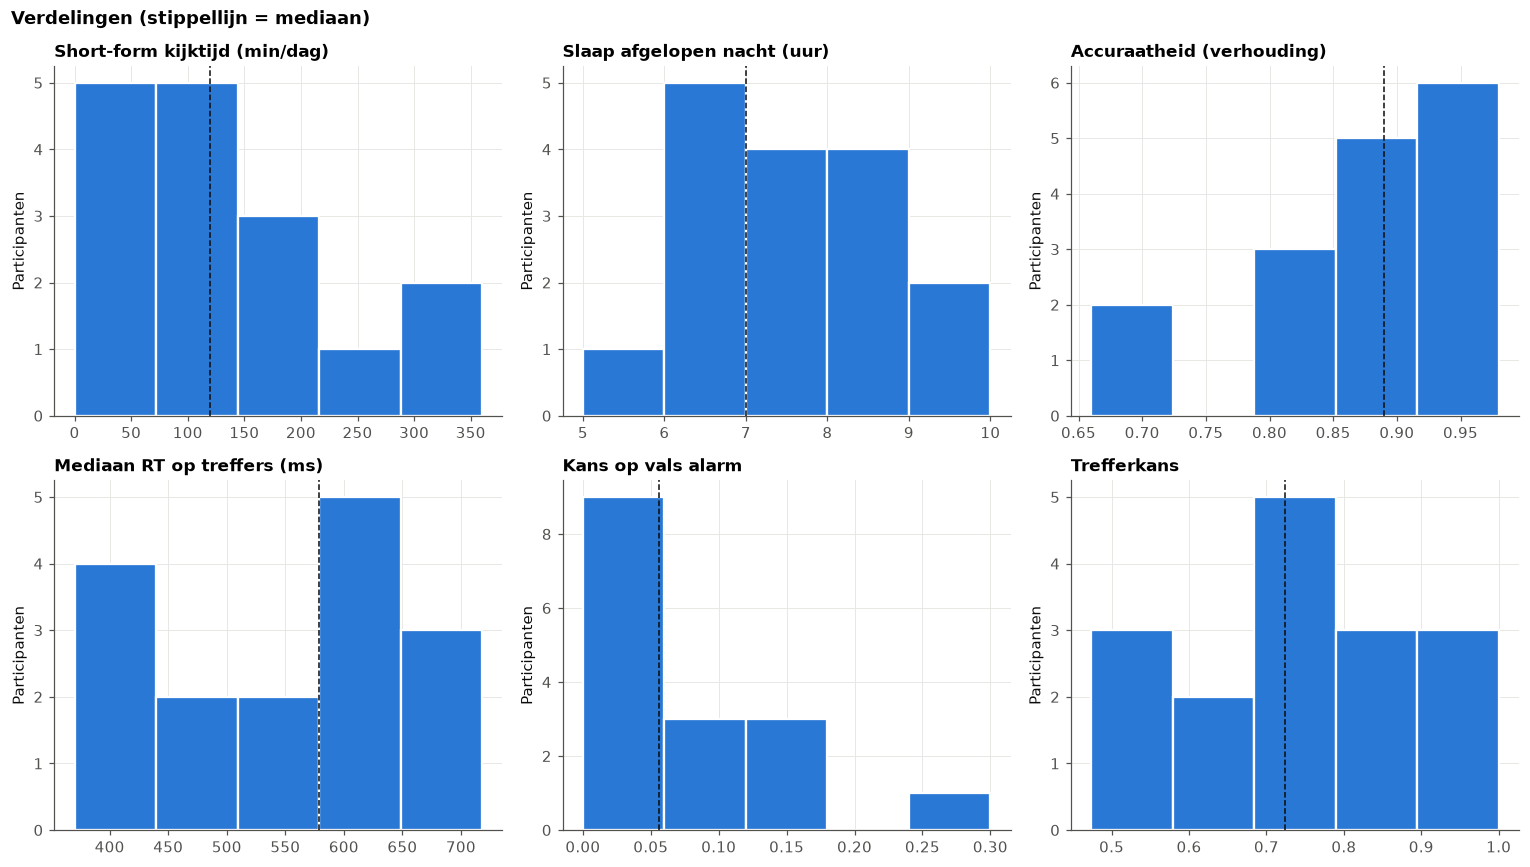

In [151]:
labels = {
    "shortform_min": "Short-form kijktijd (min/dag)",
    "slaap": "Slaap afgelopen nacht (uur)",
    "accuracy": "Accuraatheid (verhouding)",
    "rt_median": "Mediaan RT op treffers (ms)",
    "fa_rate": "Kans op vals alarm",
    "hit_rate": "Trefferkans"
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (v, lab) in zip(axes.flat, labels.items()):
    x = dataset[v].dropna()
    ax.hist(x, bins="auto", color=BLUE, edgecolor="white", linewidth=1.5)
    ax.axvline(x.median(), color=INK, linewidth=1, linestyle="--")
    ax.set_title(lab, loc="left")
    ax.set_ylabel("Participanten")
fig.suptitle("Verdelingen (stippellijn = mediaan)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

display(fig)